Caio Madeira

In [2]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, cross_val_predict, StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

In [3]:
train_df = pd.read_csv("data/train.csv")
test_df = pd.read_csv("data/test.csv")

In [4]:
train_df

,id,review,label
0,0,<p></p>not worth the money,good
1,1,Love magazines full of non important informati...,good
2,2,I have been subscribing to this magazine for y...,good
3,3,I was amazed at how quickly this came in the m...,good
4,4,...<br>I can't get Hearst to extend my subscri...,good
...,...,...,...
6661,6661,Love this magazine! Informative and interesting!,good
6662,6662,Excellent and interesting articles. Quite a lo...,good
6663,6663,</li>not all of us have kindle fire or an ipho...,good
6664,6664,Came exactly as expected - great price/year. ...,good


In [5]:
train_df.shape, test_df.shape

((6666, 3), (1000, 2))

In [6]:
train_df["label"].value_counts()

label
good    3333
bad     3333
Name: count, dtype: int64

In [7]:
train_df["review"].isna().sum()

np.int64(0)

In [8]:
train_df["review"].duplicated().sum()

np.int64(0)

In [9]:
train_df["review"].str.len().describe().round(1)

count    6666.0
mean       97.6
std        47.7
min         9.0
25%        55.2
50%       101.0
75%       136.0
max       210.0
Name: review, dtype: float64

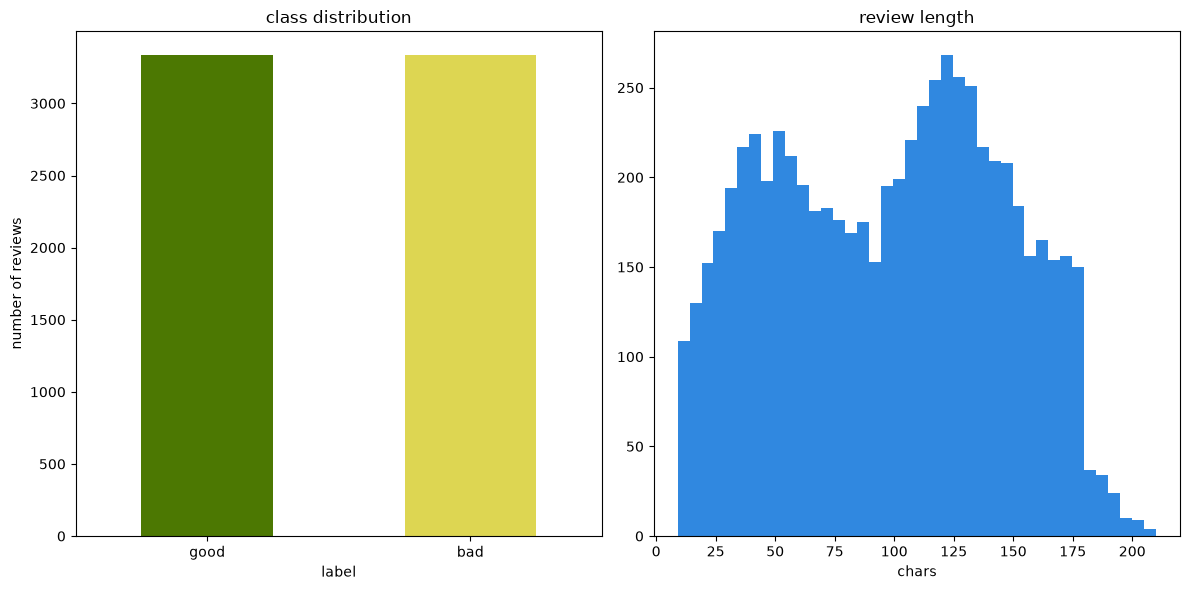

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
train_df["label"].value_counts().plot(kind="bar", ax=ax[0], color=['#4c7802', "#DDD652"], rot=0)
ax[0].set_title("class distribution")
ax[0].set_ylabel("number of reviews")
ax[1].hist(train_df["review"].str.len(), bins=40, color="#3088e0")
ax[1].set_title("review length")
ax[1].set_xlabel("chars")
plt.tight_layout()
plt.show()

In [11]:
X_train, X_val, y_train, y_val = train_test_split(train_df["review"], train_df["label"], test_size=0.2, random_state=42, stratify=train_df["label"])
pipe = make_pipeline(CountVectorizer(), MultinomialNB())
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('countvectorizer', ...), ('multinomialnb', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U4](2,)","['bad','good']"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True


In [12]:
round(accuracy_score(y_val, pipe.predict(X_val)), 4)

0.6192

usando countvectorizer (bag of words) e multinomialnb (naive bayes classifier). segundo o prof eh uma trefa facil que daria pra ser resolvida sem muito esforço. Se, nesse caso, deu 63% com um dataset bem balanceado, a minha prioridade foi fazer algum preprocessamento dos dados

as tags html são um problema, algumas instâncias com tags recebiam uma label contradizente ao que de fato rola de sentimento nela

In [14]:
train_df["has_html_tag"] = train_df["review"].str.contains("<")
test_df["has_html_tag"] = test_df["review"].str.contains("<")

In [15]:
train_df["has_html_tag"].sum()

np.int64(2668)

In [16]:
test_df["has_html_tag"].sum()

np.int64(1)

In [17]:
cleaned = train_df[~train_df["has_html_tag"]]
dirty = train_df[train_df["has_html_tag"]]

In [18]:
cleaned

,id,review,label,has_html_tag
1,1,Love magazines full of non important informati...,good,False
2,2,I have been subscribing to this magazine for y...,good,False
3,3,I was amazed at how quickly this came in the m...,good,False
7,7,This is entirely too expensive,bad,False
8,8,This magazine really has advice to help you wr...,good,False
...,...,...,...,...
6660,6660,"What can I say. It's Vanity Fair, the best in ...",good,False
6661,6661,Love this magazine! Informative and interesting!,good,False
6662,6662,Excellent and interesting articles. Quite a lo...,good,False
6664,6664,Came exactly as expected - great price/year. ...,good,False


In [19]:
dirty

,id,review,label,has_html_tag
0,0,<p></p>not worth the money,good,True
4,4,...<br>I can't get Hearst to extend my subscri...,good,True
5,5,11 year old loved it -- and even enjoyed looki...,bad,True
6,6,Waste of time<li>on,good,True
12,12,"Mostly ads and like the other reviewer said, t...",good,True
...,...,...,...,...
6655,6655,This magazine is mostly adds and ugly fashion ...,good,True
6656,6656,<li>It's a lifestyle magazine not fashion. I d...,good,True
6657,6657,</table>best for following Sunday Mass ever.<s...,bad,True
6659,6659,<head>Nothing new here. Had hoped for new idea...,good,True


In [20]:
pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True), MultinomialNB(alpha=0.3))

cross_val = StratifiedKFold(n_splits=5, shuffle=True, random_state=41)
acc_cleaned = cross_val_score(pipe, cleaned["review"], cleaned["label"], cv=cross_val).mean()
pipe.fit(cleaned["review"], cleaned["label"])
acc_dirty = accuracy_score(dirty["label"], pipe.predict(dirty["review"]))

In [21]:
print(f"acc without html tags in cross validation={acc_cleaned:.4f}")
print(f"acc with html tags in same model={acc_dirty:.4f}")

acc without html tags in cross validation=0.9567
acc with html tags in same model=0.0424


o modelo vai bem em reviews sem tags html e erra bastante em review com html. review que recebeu tags em html pode ter tido o rotulo invertido.

In [22]:
from parse import parse_html_tags, invert_html_labels

train_df["text"] = train_df["review"].apply(parse_html_tags)
test_df["text"] = test_df["review"].apply(parse_html_tags)

In [23]:
train_df["y"] = np.where(train_df["has_html_tag"], train_df["label"].apply(invert_html_labels), train_df["label"])

In [24]:
train_df["text"]

0                                     not worth the money
1       Love magazines full of non important informati...
2       I have been subscribing to this magazine for y...
3       I was amazed at how quickly this came in the m...
4       ... I can't get Hearst to extend my subscripti...
                              ...                        
6661     Love this magazine! Informative and interesting!
6662    Excellent and interesting articles. Quite a lo...
6663    not all of us have kindle fire or an iphone/ip...
6664    Came exactly as expected - great price/year. W...
6665    Not much of style but as you flip pages all yo...
Name: text, Length: 6666, dtype: str

In [26]:
for k, v in train_df[train_df["has_html_tag"]].sample(5, random_state=1).iterrows():
    print(f"has tag[{v['label']}] {v['review'][:95]}")
    print(f"no tag [{v['y']}] {v['text'][:95]}")


has tag[bad] </table>best for following Sunday Mass ever.<span class="symbol">
no tag [good] best for following Sunday Mass ever.
has tag[good] </li></dd>didn't care for it
no tag [bad] didn't care for it
has tag[good] <li class="api apilevel-">I thought this was teen titans with Scooby doo the first magazine arr
no tag [bad] I thought this was teen titans with Scooby doo the first magazine arrived and I see no teen tit
has tag[good] </div>Not a magazine ...it is one big advertisement.  I had high hopes for this publication.  S
no tag [bad] Not a magazine ...it is one big advertisement. I had high hopes for this publication. Stick wit
has tag[bad] Great magazine with both recipes and foodie articles. A lot of info packed into a magazine anyo
no tag [good] Great magazine with both recipes and foodie articles. A lot of info packed into a magazine anyo


verificando se continua balanceado

In [27]:
train_df["y"].value_counts()

y
bad     3333
good    3333
Name: count, dtype: int64

como indicaod em aula, usar o countvectorizer (bag of words) é um caminho viavel e é usado no codigo de exemplo

tdidf também foi recomendado e eu uso pra contornar um problema do bag of words. O bow vai calcular palavras frequentes em todos os documentos, então, por exemplo, stop words podem pesar tanto quanto palavras mais "raras". o calculo do tf idf meio que corrige isso.

Outra questão é utilizar ngramas (no caso bigramas) pro vectorizer considerar palavras isoladas e pares  consecutivos. 

In [49]:
example = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
X2 = example.fit_transform(train_df["text"])
X2

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 195006 stored elements and shape (6666, 47833)>

tenho uma sparse matrix

In [30]:
X = train_df["text"]
y = train_df["y"]
cross_val = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [31]:
models = { 
            "bayes(bow)": make_pipeline(CountVectorizer(), MultinomialNB()), 
            "bayes(tf-idf)": make_pipeline(TfidfVectorizer(ngram_range=(1,2), sublinear_tf=True), MultinomialNB(alpha=0.3)),
            "knn(cos)": make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2), KNeighborsClassifier(n_neighbors=41, metric="cosine", weights="distance")),
            "decision tree": make_pipeline(TfidfVectorizer(min_df=2), DecisionTreeClassifier(max_depth=40, random_state=42)),
        }

In [32]:
results = {}
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cross_val, scoring="accuracy", n_jobs=-1)
    results[name] = scores
    print(f"name={name:32s}, mean={scores.mean():.4f}, std={scores.std():.4f}")

name=bayes(bow)                      , mean=0.9566, std=0.0044
name=bayes(tf-idf)                   , mean=0.9608, std=0.0039
name=knn(cos)                        , mean=0.9349, std=0.0030
name=decision tree                   , mean=0.9286, std=0.0048


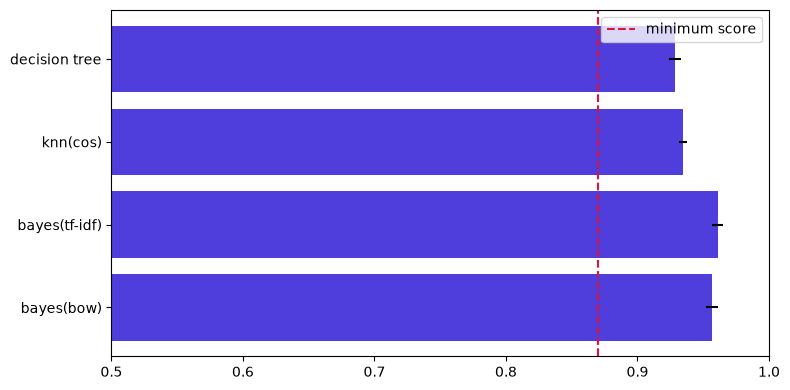

In [33]:
fig, ax = plt.subplots(figsize=(8, 4))
names = list(results)
means = []
errors = []
for n in names:
    means.append(results[n].mean())
    errors.append(results[n].std())
ax.barh(names, means, xerr=errors, color="#4f3ddc")
ax.axvline(0.87, color="crimson", ls="--", label="minimum score")
ax.set_xlim(0.5, 1.0)
ax.set_label("acc (cross validation 5 folds)")
ax.legend()
plt.tight_layout()
plt.show()

In [34]:
tfidf_configs = []

for ngram in [(1, 1), (1, 2), (1, 3)]:
    for alpha in [0.1, 0.3, 0.5, 1.0]:
        pipe = make_pipeline(TfidfVectorizer(ngram_range=ngram, sublinear_tf=True), MultinomialNB(alpha=alpha))
        score = cross_val_score(pipe, X, y, cv=cross_val, n_jobs=-1).mean()
        print(f"ngram={ngram}, alpha={alpha:<4} -> {score:.4f}")
        tfidf_configs.append({
            "score": score,
            "ngram": ngram,
            "alpha": alpha
        })

ngram=(1, 1), alpha=0.1  -> 0.9397
ngram=(1, 1), alpha=0.3  -> 0.9463
ngram=(1, 1), alpha=0.5  -> 0.9490
ngram=(1, 1), alpha=1.0  -> 0.9496
ngram=(1, 2), alpha=0.1  -> 0.9583
ngram=(1, 2), alpha=0.3  -> 0.9608
ngram=(1, 2), alpha=0.5  -> 0.9604
ngram=(1, 2), alpha=1.0  -> 0.9583
ngram=(1, 3), alpha=0.1  -> 0.9586
ngram=(1, 3), alpha=0.3  -> 0.9593
ngram=(1, 3), alpha=0.5  -> 0.9602
ngram=(1, 3), alpha=1.0  -> 0.9589


In [35]:
best_config = max(tfidf_configs, key=lambda c: c['score'])
best_config['ngram'], best_config['alpha']

((1, 2), 0.3)

In [36]:
final_model = make_pipeline(TfidfVectorizer(ngram_range=best_config['ngram'], sublinear_tf=True), MultinomialNB(alpha=best_config['alpha']))

y_pred = cross_val_predict(final_model, X, y, cv=cross_val, n_jobs=-1)
print(classification_report(y, y_pred, digits=4))

              precision    recall  f1-score   support

         bad     0.9770    0.9439    0.9602      3333
        good     0.9457    0.9778    0.9615      3333

    accuracy                         0.9608      6666
   macro avg     0.9614    0.9608    0.9608      6666
weighted avg     0.9614    0.9608    0.9608      6666



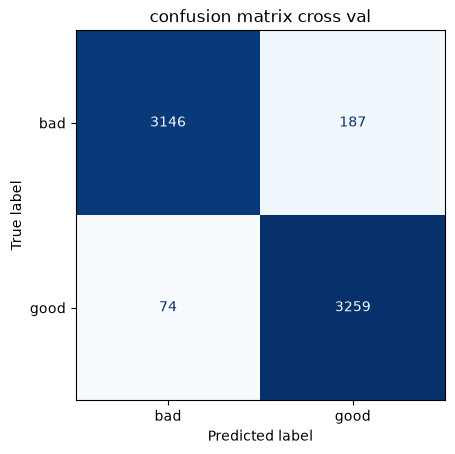

In [43]:
ConfusionMatrixDisplay(confusion_matrix(y, y_pred, labels=["bad", "good"]), display_labels=["bad", "good"]).plot(cmap="Blues", colorbar=False)
plt.title("confusion matrix cross val"); plt.show()

In [44]:
final_model.fit(X, y)
vectorizer = final_model.named_steps["tfidfvectorizer"]
nb = final_model.named_steps["multinomialnb"]

terms = np.array(vectorizer.get_feature_names_out())

ibad, igood = list(nb.classes_).index("bad"), list(nb.classes_).index("good")
weight = nb.feature_log_prob_[igood] - nb.feature_log_prob_[ibad]
order = np.argsort(weight)

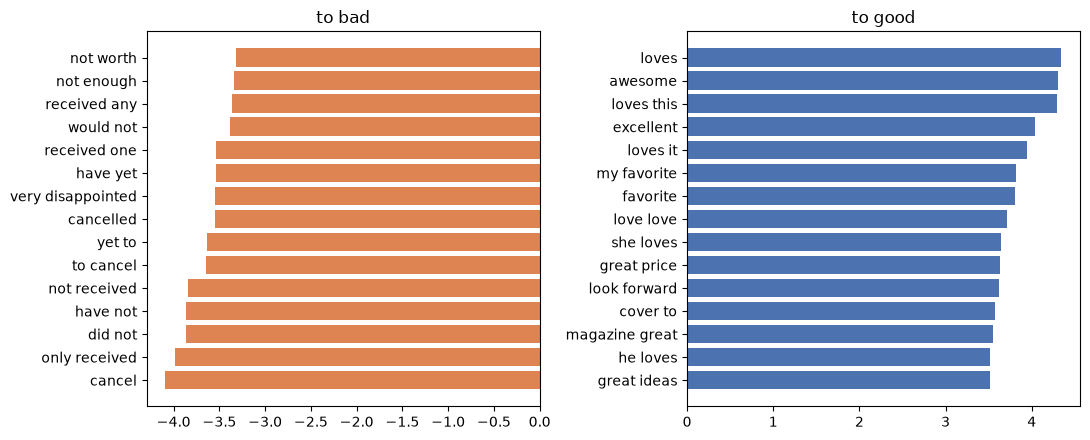

In [45]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].barh(terms[order[:15]], weight[order[:15]], color="#DD8452")
ax[0].set_title("to bad")
ax[1].barh(terms[order[-15:]], weight[order[-15:]], color="#4C72B0")
ax[1].set_title("to good")
plt.tight_layout(); plt.show()

In [46]:
final_model.fit(train_df["text"], train_df["y"])
pred_test = final_model.predict(test_df["text"])

submission = pd.DataFrame({"id": test_df["id"], "label": pred_test})
submission.to_csv("submission.csv", index=False)

In [47]:
print(submission["label"].value_counts(), "\n")
print(submission.head())

label
good    509
bad     491
Name: count, dtype: int64 

     id label
0  6666  good
1  6667   bad
2  6668   bad
3  6669  good
4  6670   bad
